# Project Figures

## Set Up
If you want to use your own experimental results to create figures, update the CSV file paths in the Setup section.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_serial = pd.read_csv("../results/serial/serial_50iter_1565209.stdct-mgmt-02.csv")
df_strong = pd.read_csv("../results/mpi/strong_all_1569183.stdct-mgmt-02.csv")
df_weak = pd.read_csv("../results/mpi/weak_all_1561000.stdct-mgmt-02.csv")
df_cpu = pd.concat([
    pd.read_csv("../results/cpu/hybrid_16x4.csv"),
    pd.read_csv("../results/cpu/hybrid_32x2.csv"),
    pd.read_csv("../results/cpu/hybrid_64x1.csv")
], ignore_index=True)
df_gpu = pd.read_csv("../results/gpu/gpu.csv")

## 1. Serial Runtime

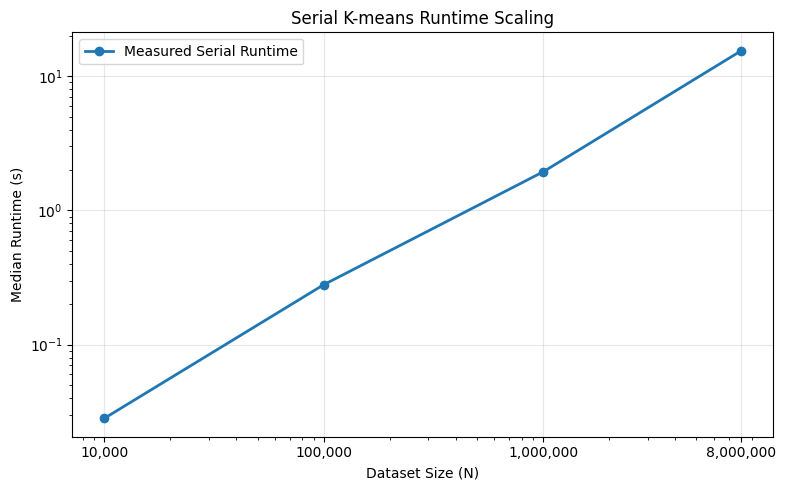

In [2]:
time_col = "time_s"

serial_median = (
    df_serial.groupby("N", as_index=False)[time_col]
    .median()
    .sort_values("N")
)

N = serial_median["N"].to_numpy()
runtime = serial_median[time_col].to_numpy()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    N,
    runtime,
    marker="o",
    linewidth=2,
    label="Measured Serial Runtime"
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(N)
ax.set_xticklabels([f"{n:,}" for n in N])
ax.set_xlabel("Dataset Size (N)")
ax.set_ylabel("Median Runtime (s)")
ax.set_title("Serial K-means Runtime Scaling")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("../figures/serial_runtime_scaling.png", dpi=300, bbox_inches="tight")
plt.show()

## 2. MPI Strong Scaling

In [3]:
strong_median = (
    df_strong.groupby("ranks", as_index=False)["time_s"]
    .median()
    .sort_values("ranks")
)
serial_time = df_serial.loc[
    df_serial["N"] == 8000000, "time_s"
].median()

strong_median["speedup"] = (
    serial_time / strong_median["time_s"]
)
strong_median["efficiency"] = (
    strong_median["speedup"] / strong_median["ranks"] * 100
)

ranks = strong_median["ranks"].to_numpy()
runtime = strong_median["time_s"].to_numpy()
speedup = strong_median["speedup"].to_numpy()
efficiency = strong_median["efficiency"].to_numpy()
x = np.arange(len(ranks))

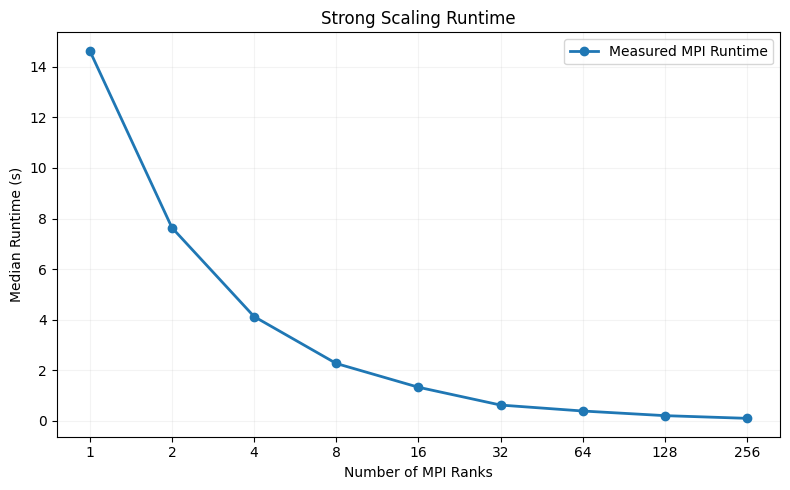

In [4]:
# Strong Scaling Runtime
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    x, runtime,
    marker="o",
    linewidth=2,
    label="Measured MPI Runtime"
)
ax.set_xticks(x)
ax.set_xticklabels(ranks)
ax.set_xlabel("Number of MPI Ranks")
ax.set_ylabel("Median Runtime (s)")
ax.set_title("Strong Scaling Runtime")
ax.grid(True, which="major", alpha=0.15)
ax.grid(False, which="minor")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/strong_scaling_runtime.png", dpi=300, bbox_inches="tight")
plt.show()

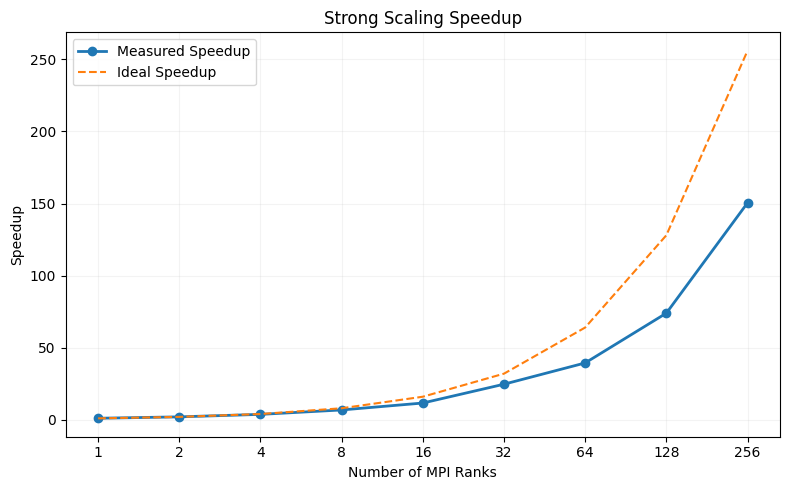

In [5]:
# Strong Scaling Speedup
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    x, speedup,
    marker="o",
    linewidth=2,
    label="Measured Speedup"
)
ax.plot(
    x, ranks,
    linestyle="--",
    linewidth=1.5,
    label="Ideal Speedup"
)
ax.set_xticks(x)
ax.set_xticklabels(ranks)
ax.set_xlabel("Number of MPI Ranks")
ax.set_ylabel("Speedup")
ax.set_title("Strong Scaling Speedup")
ax.grid(True, which="major", alpha=0.15)
ax.grid(False, which="minor")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/strong_scaling_speedup.png", dpi=300, bbox_inches="tight")
plt.show()

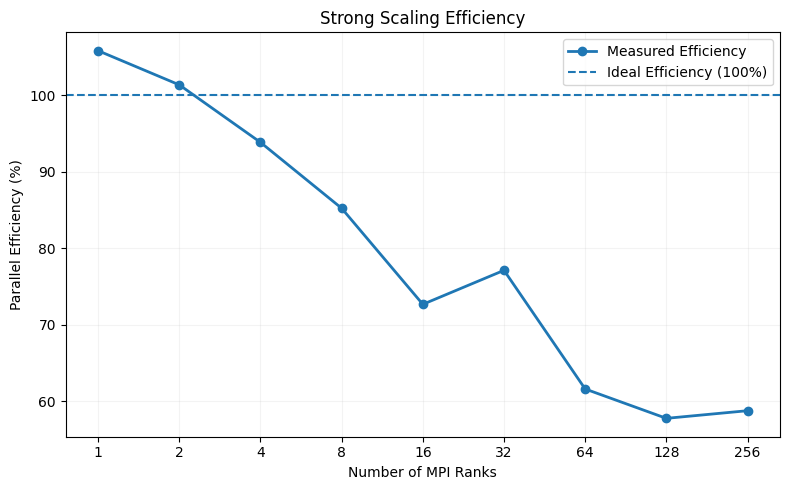

In [6]:
# Strong Scaling Efficiency
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    x,
    efficiency,
    marker="o",
    linewidth=2,
    label="Measured Efficiency"
)
ax.axhline(
    100,
    linestyle="--",
    linewidth=1.5,
    label="Ideal Efficiency (100%)"
)
ax.set_xticks(x)
ax.set_xticklabels(ranks)
ax.set_xlabel("Number of MPI Ranks")
ax.set_ylabel("Parallel Efficiency (%)")
ax.set_title("Strong Scaling Efficiency")
ax.grid(True, which="major", alpha=0.15)
ax.grid(False, which="minor")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/strong_scaling_efficiency.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. MPI Week Scaling

In [7]:
median_df = (
    df_weak.groupby("ranks", as_index=False)["time_s"]
    .median()
    .sort_values("ranks")
)
ranks = median_df["ranks"].to_numpy()
runtime = median_df["time_s"].to_numpy()
efficiency = runtime[0] / runtime * 100
x = np.arange(len(ranks))

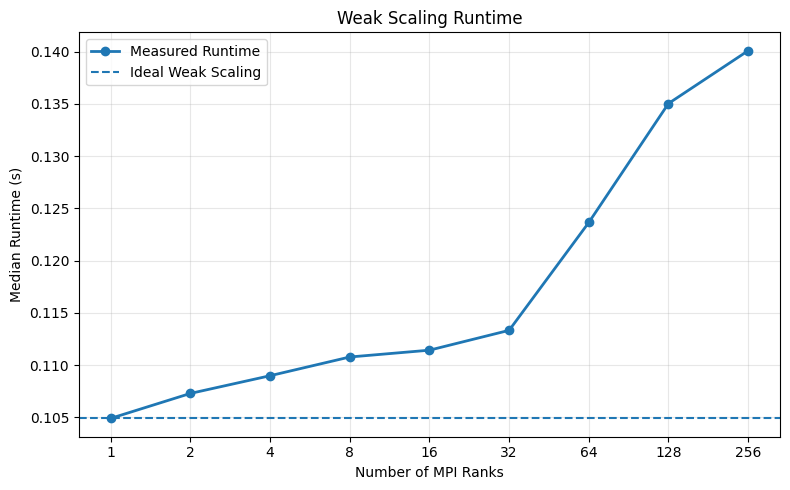

In [8]:
# Weak Scaling Runtime
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, runtime, marker="o", linewidth=2, label="Measured Runtime")
ax.axhline(runtime[0], linestyle="--", label="Ideal Weak Scaling")
ax.set_xticks(x)
ax.set_xticklabels(ranks)
ax.set_xlabel("Number of MPI Ranks")
ax.set_ylabel("Median Runtime (s)")
ax.set_title("Weak Scaling Runtime")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("../figures/weak_scaling_runtime.png", dpi=300, bbox_inches="tight")
plt.show()

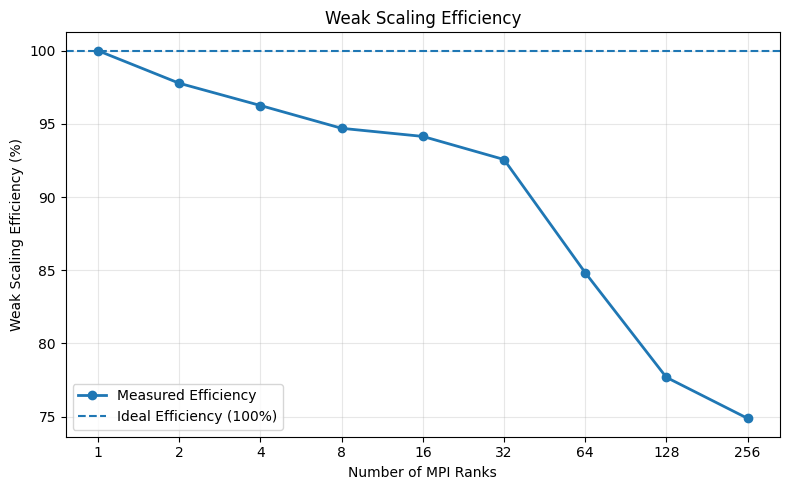

In [9]:
# Weak Scaling Efficiency
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, efficiency, marker="o", linewidth=2, label="Measured Efficiency")
ax.axhline(100, linestyle="--", label="Ideal Efficiency (100%)")
ax.set_xticks(x)
ax.set_xticklabels(ranks)
ax.set_xlabel("Number of MPI Ranks")
ax.set_ylabel("Weak Scaling Efficiency (%)")
ax.set_title("Weak Scaling Efficiency")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("../figures/weak_scaling_efficiency.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. MPI Communication Time

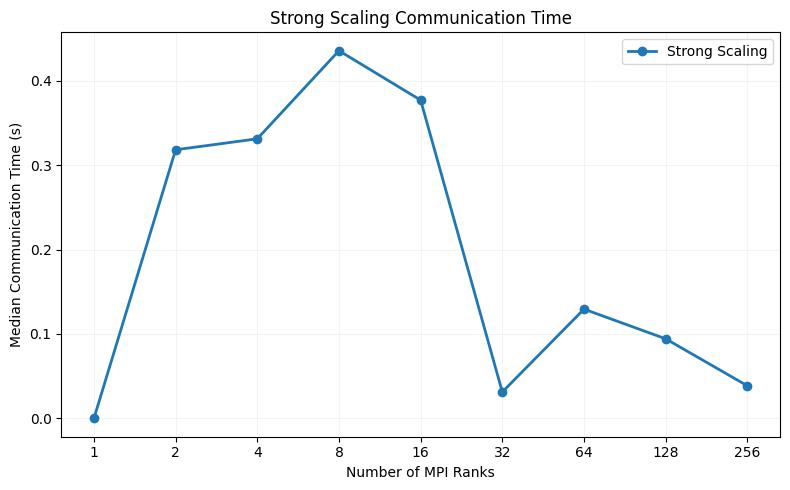

In [10]:
# Strong Communication Time
strong_comm = (
    df_strong.groupby("ranks", as_index=False)["comm_max_s"]
    .median()
    .sort_values("ranks")
)
ranks = strong_comm["ranks"].to_numpy()
x = np.arange(len(ranks))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    x,
    strong_comm["comm_max_s"],
    marker="o",
    linewidth=2,
    label="Strong Scaling"
)
ax.set_xticks(x)
ax.set_xticklabels(ranks)
ax.set_xlabel("Number of MPI Ranks")
ax.set_ylabel("Median Communication Time (s)")
ax.set_title("Strong Scaling Communication Time")
ax.grid(True, which="major", alpha=0.15)
ax.grid(False, which="minor")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/strong_scaling_communication.png", dpi=300, bbox_inches="tight")
plt.show()

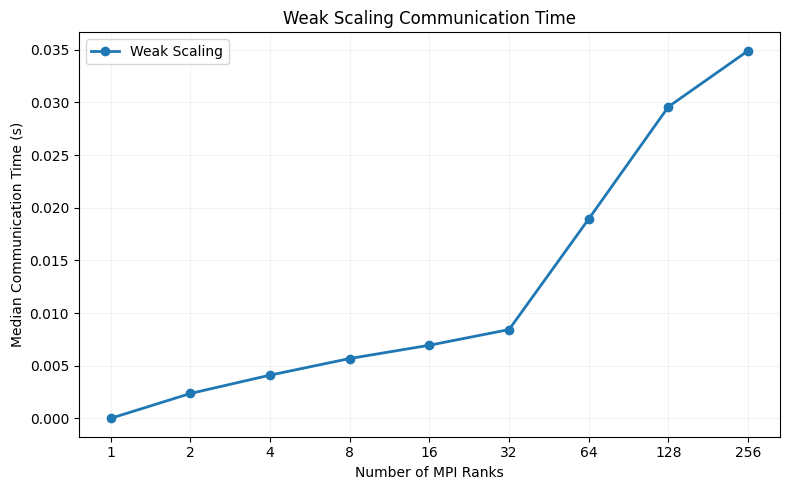

In [11]:
# Weak Communication Time
weak_comm = (
    df_weak.groupby("ranks", as_index=False)["comm_max_s"]
    .median()
    .sort_values("ranks")
)
ranks = weak_comm["ranks"].to_numpy()
x = np.arange(len(ranks))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    x,
    weak_comm["comm_max_s"],
    marker="o",
    linewidth=2,
    label="Weak Scaling"
)
ax.set_xticks(x)
ax.set_xticklabels(ranks)
ax.set_xlabel("Number of MPI Ranks")
ax.set_ylabel("Median Communication Time (s)")
ax.set_title("Weak Scaling Communication Time")
ax.grid(True, which="major", alpha=0.15)
ax.grid(False, which="minor")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/weak_scaling_communication.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. MPI+OpenMP

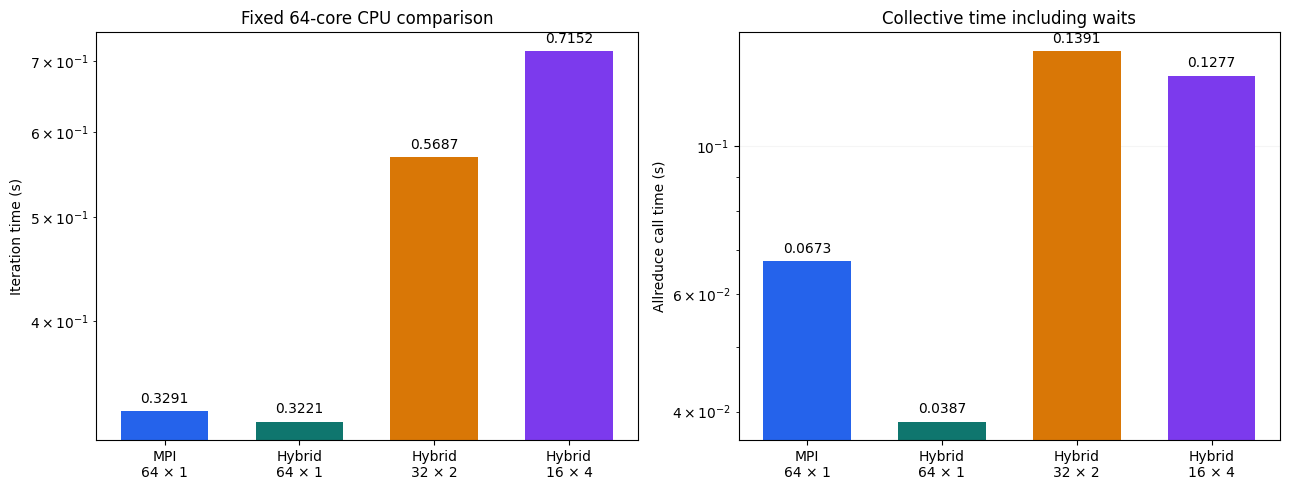

In [12]:
# CPU Hybrid Comparison
groups = [
    df_cpu[(df_cpu["version"] == "mpi") & (df_cpu["ranks"] == 64)],
    df_cpu[(df_cpu["version"] == "hybrid") & (df_cpu["ranks"] == 64) & (df_cpu["threads"] == 1)],
    df_cpu[(df_cpu["version"] == "hybrid") & (df_cpu["ranks"] == 32) & (df_cpu["threads"] == 2)],
    df_cpu[(df_cpu["version"] == "hybrid") & (df_cpu["ranks"] == 16) & (df_cpu["threads"] == 4)]
]

labels = ["MPI\n64 × 1", "Hybrid\n64 × 1", "Hybrid\n32 × 2", "Hybrid\n16 × 4"]
colors = ["#2563eb", "#0f766e", "#d97706", "#7c3aed"]

runtime = [g["time_s"].median() for g in groups]
communication = [g["comm_max_s"].median() for g in groups]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, values, ylabel, title in zip(
    axes,
    [runtime, communication],
    ["Iteration time (s)", "Allreduce call time (s)"],
    ["Fixed 64-core CPU comparison", "Collective time including waits"]
):
    bars = ax.bar(labels, values, color=colors, width=0.65)
    ax.set_yscale("log")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis="y", which="major", alpha=0.12)
    ax.grid(False, which="minor")
    ax.set_axisbelow(True)

    for bar, value in zip(bars, values):
        ax.annotate(
            f"{value:.4f}",
            (bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center"
        )

fig.tight_layout()
fig.savefig("../figures/cpu_hybrid_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


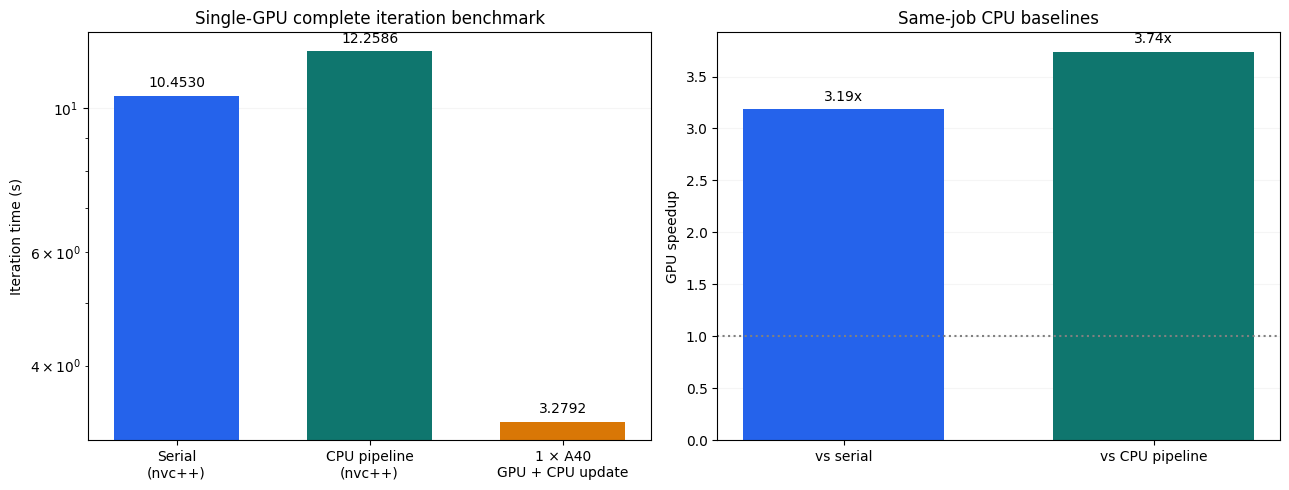

In [13]:
# GPU Comparison
versions = ["serial", "cpu_assignment", "gpu"]
labels = ["Serial\n(nvc++)", "CPU pipeline\n(nvc++)", "1 × A40\nGPU + CPU update"]
colors = ["#2563eb", "#0f766e", "#d97706"]

runtime = (
    df_gpu.groupby("version")["time_s"]
    .median()
    .reindex(versions)
    .to_numpy()
)

speedup = [
    runtime[0] / runtime[2],
    runtime[1] / runtime[2]
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bars = axes[0].bar(labels, runtime, color=colors, width=0.65)
axes[0].set_yscale("log")
axes[0].set_ylabel("Iteration time (s)")
axes[0].set_title("Single-GPU complete iteration benchmark")
axes[0].grid(axis="y", which="major", alpha=0.12)
axes[0].grid(False, which="minor")
axes[0].set_axisbelow(True)

for bar, value in zip(bars, runtime):
    axes[0].annotate(
        f"{value:.4f}",
        (bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center"
    )

bars = axes[1].bar(
    ["vs serial", "vs CPU pipeline"],
    speedup,
    color=colors[:2],
    width=0.65
)

axes[1].axhline(1, color="gray", linestyle=":")
axes[1].set_ylabel("GPU speedup")
axes[1].set_title("Same-job CPU baselines")
axes[1].grid(axis="y", alpha=0.12)
axes[1].set_axisbelow(True)

for bar, value in zip(bars, speedup):
    axes[1].annotate(
        f"{value:.2f}x",
        (bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center"
    )

fig.tight_layout()
fig.savefig("../figures/gpu_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


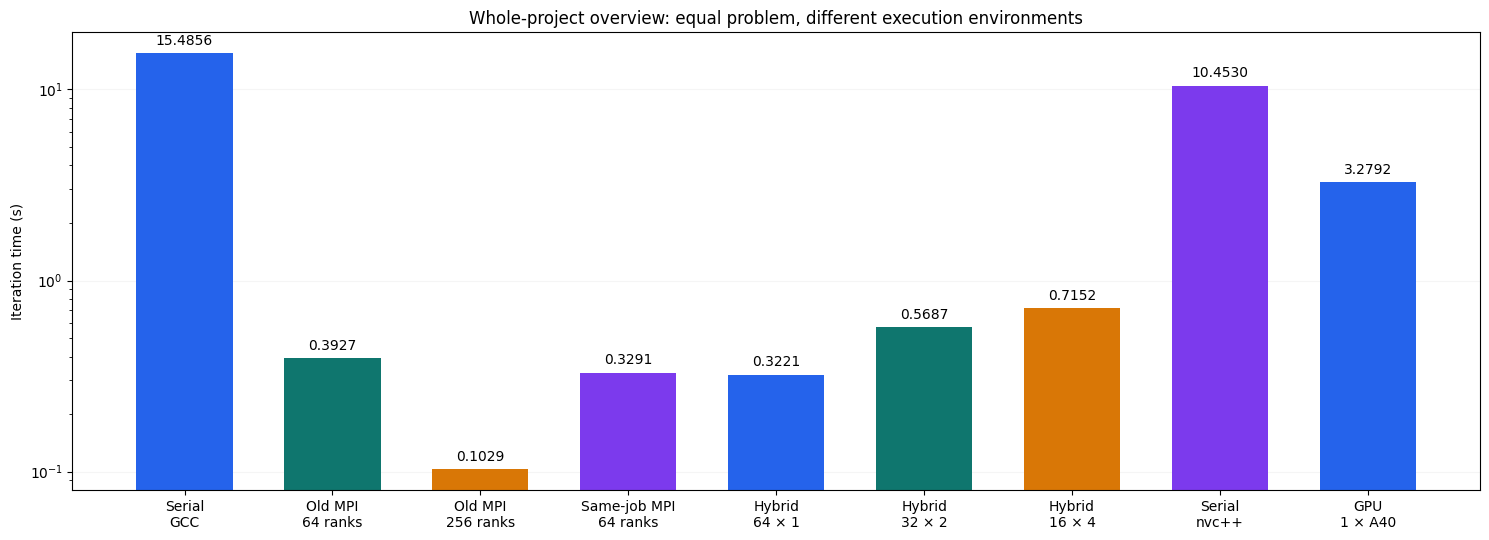

In [14]:
# All Versions Overview
df_cpu = pd.concat([
    pd.read_csv("../results/cpu/hybrid_16x4.csv"),
    pd.read_csv("../results/cpu/hybrid_32x2.csv"),
    pd.read_csv("../results/cpu/hybrid_64x1.csv")
], ignore_index=True)

df_gpu = pd.read_csv("../results/gpu/gpu.csv")

groups = [
    df_serial[df_serial["N"] == 8000000],
    df_strong[df_strong["ranks"] == 64],
    df_strong[df_strong["ranks"] == 256],
    df_cpu[(df_cpu["version"] == "mpi") & (df_cpu["ranks"] == 64)],
    df_cpu[(df_cpu["version"] == "hybrid") & (df_cpu["ranks"] == 64) & (df_cpu["threads"] == 1)],
    df_cpu[(df_cpu["version"] == "hybrid") & (df_cpu["ranks"] == 32) & (df_cpu["threads"] == 2)],
    df_cpu[(df_cpu["version"] == "hybrid") & (df_cpu["ranks"] == 16) & (df_cpu["threads"] == 4)],
    df_gpu[df_gpu["version"] == "serial"],
    df_gpu[df_gpu["version"] == "gpu"]
]

labels = [
    "Serial\nGCC", "Old MPI\n64 ranks", "Old MPI\n256 ranks",
    "Same-job MPI\n64 ranks", "Hybrid\n64 × 1", "Hybrid\n32 × 2",
    "Hybrid\n16 × 4", "Serial\nnvc++", "GPU\n1 × A40"
]

colors = [
    "#2563eb", "#0f766e", "#d97706",
    "#7c3aed", "#2563eb", "#0f766e",
    "#d97706", "#7c3aed", "#2563eb"
]

runtime = [g["time_s"].median() for g in groups]

fig, ax = plt.subplots(figsize=(15, 5.5))

bars = ax.bar(labels, runtime, color=colors, width=0.65)

ax.set_yscale("log")
ax.set_ylabel("Iteration time (s)")
ax.set_title("Whole-project overview: equal problem, different execution environments")
ax.grid(axis="y", which="major", alpha=0.12)
ax.grid(False, which="minor")
ax.set_axisbelow(True)

for bar, value in zip(bars, runtime):
    ax.annotate(
        f"{value:.4f}",
        (bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center"
    )

fig.tight_layout()
fig.savefig("../figures/all_versions_overview.png", dpi=300, bbox_inches="tight")
plt.show()


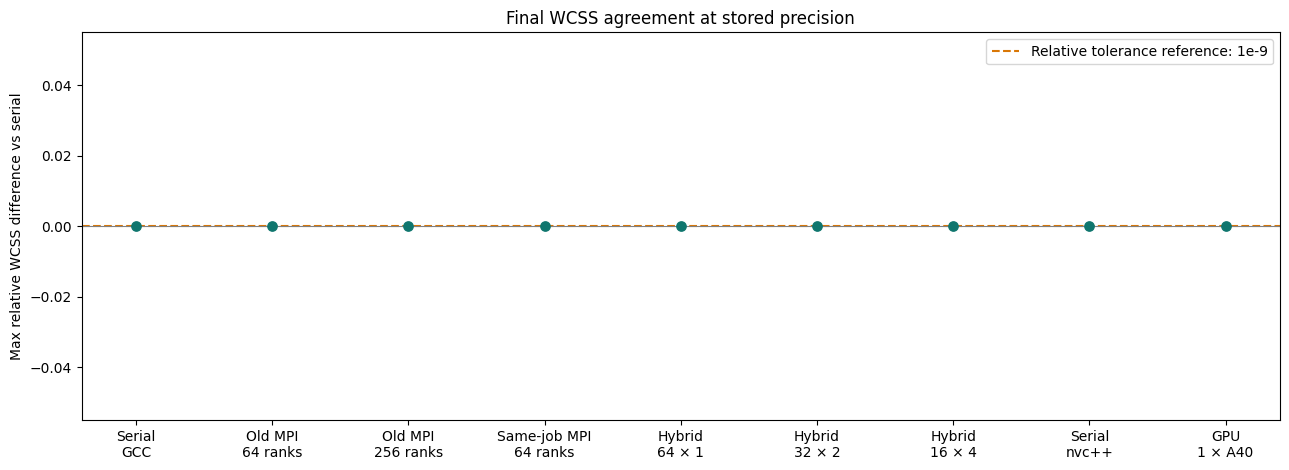

In [15]:
# WCSS Validation
groups = [
    df_serial[df_serial["N"] == 8000000],
    df_strong[df_strong["ranks"] == 64],
    df_strong[df_strong["ranks"] == 256],
    df_cpu[(df_cpu["version"] == "mpi") & (df_cpu["ranks"] == 64)],
    df_cpu[(df_cpu["version"] == "hybrid") & (df_cpu["ranks"] == 64) & (df_cpu["threads"] == 1)],
    df_cpu[(df_cpu["version"] == "hybrid") & (df_cpu["ranks"] == 32) & (df_cpu["threads"] == 2)],
    df_cpu[(df_cpu["version"] == "hybrid") & (df_cpu["ranks"] == 16) & (df_cpu["threads"] == 4)],
    df_gpu[df_gpu["version"] == "serial"],
    df_gpu[df_gpu["version"] == "gpu"]
]

labels = [
    "Serial\nGCC", "Old MPI\n64 ranks", "Old MPI\n256 ranks",
    "Same-job MPI\n64 ranks", "Hybrid\n64 × 1", "Hybrid\n32 × 2",
    "Hybrid\n16 × 4", "Serial\nnvc++", "GPU\n1 × A40"
]

reference = groups[0]["wcss"].median()

relative_difference = [
    np.max(np.abs(g["wcss"].dropna() - reference) / abs(reference))
    for g in groups
]

fig, ax = plt.subplots(figsize=(13, 4.8))

x = np.arange(len(labels))

ax.scatter(x, relative_difference, s=45, color="#0f766e", zorder=3)
ax.axhline(
    1e-9,
    linestyle="--",
    color="#d97706",
    label="Relative tolerance reference: 1e-9"
)
ax.axhline(0, color="gray", linewidth=0.8)

ax.set_xticks(x, labels)
ax.set_ylabel("Max relative WCSS difference vs serial")
ax.set_title("Final WCSS agreement at stored precision")
ax.grid(False)
ax.legend()

fig.tight_layout()
fig.savefig("../figures/wcss_validation.png", dpi=300, bbox_inches="tight")
plt.show()
